# EXP019 EDA — P'Q'座標系の変換係数・ラベル範囲分析

EXP019 の各 pq_rescale_mode（eye_height / eye_scale / mean_pq_dist）における
変換後 t' の分布を可視化し、factor/label_t_min /label_t_max の適切な値を探索する

## 1. データ読み込み

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

NOTEBOOK_DIR = Path(".").resolve()
ROOT = NOTEBOOK_DIR.parent
sys.path.insert(0, str(ROOT))

from eyeliner.data.dataset import load_manifest
from eyeliner.data.weights import compute_eye_meta
from eyeliner.data.patch_utils import compute_pq_rescale

DIR = ROOT / "experiments/EXP019_pq_transform"

manifest_train = load_manifest(str(DIR / "manifests/manifest_train.csv"))
manifest_test = load_manifest(str(DIR / "manifests/manifest_test.csv"))
manifest = manifest_train + manifest_test
compute_eye_meta(manifest)

conn = sqlite3.connect(ROOT / "data/samples.db")
eye_scale_df = pd.read_sql("SELECT idx, eye_scale FROM samples", conn)
conn.close()

print(f"manifest: {len(manifest)} samples")

manifest: 17095 samples


## 2. 各モードの t' 分布と label range の適合確認

In [ ]:
import io
from dataclasses import dataclass

import ipywidgets as widgets
from ipywidgets import FloatSlider, VBox, HBox
from IPython.display import display

import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
import numpy as np
from scipy.stats import gaussian_kde

plt.close("all")   # 以前の run で残った pyplot figure を掃除（他セルの inline 描画には無影響）

# ── configs ──────────────────────────────────────────────────────────
COLORS = ["#2196F3", "#F44336", "#9C27B0", "#E91E63"]


@dataclass
class DistConfig:
    label: str
    mode: str
    factor: float
    lmin: float
    lmax: float


DIST_CONFIGS = [
    DistConfig("raw t",      "none",         1.0, -1.0, 2.0),
    DistConfig("eye_height", "eye_height",   0.5, -0.25, 1.25),
    DistConfig("eye_scale",  "eye_scale",    0.2, -0.25, 1.25),
    DistConfig("mean_pq",    "mean_pq_dist", 1.0, -1.0, 2.0),
]

# ── pre-compute t' for all modes (only data-dependent parts) ─────────
MODE_KEYS = {
    "none":         None,
    "eye_height":   "eye_height",
    "mean_pq_dist": "mean_pq_dist",
    "eye_scale":    "eye_scale",
}

rec_vals = []
for rec in manifest:
    try:
        t = float(rec["t"])
        px, py = float(rec["px"]), float(rec["py"])
        qx, qy = float(rec["qx"]), float(rec["qy"])
    except (ValueError, TypeError):
        continue
    vals = {}
    for mode, key in MODE_KEYS.items():
        vals[mode] = None if key is None else float(rec.get(key, 0) or 0)
    vals["_orig_d"] = np.sqrt((qx - px)**2 + (qy - py)**2) or 1e-6
    vals["_t"] = t
    rec_vals.append(vals)


def build_distribution_fast(cfg_index, factor):
    """Recompute t_prime for a given config index + factor using pre-cached geometry."""
    mode = DIST_CONFIGS[cfg_index].mode
    ts = []
    for rv in rec_vals:
        t = rv["_t"]
        orig_d = rv["_orig_d"]
        if mode == "none":
            ts.append(t)
        else:
            xxx = max(float(rv[mode] or orig_d) * factor, 1.0)
            ts.append(0.5 + (t - 0.5) * orig_d / xxx)
    return np.asarray(ts)


def plot_distribution(ax, label, ts, lmin, lmax, color):
    ts = ts[np.isfinite(ts)]
    lo = np.percentile(ts, 0.1)
    hi = np.percentile(ts, 99.9)
    clipped = np.clip(ts, lo, hi)
    x = np.linspace(min(lo, lmin) - 0.05, max(hi, lmax) + 0.05, 500)
    kde = gaussian_kde(clipped, bw_method=0.05)
    y = kde(x)
    ax.fill_between(x, y, alpha=0.2, color=color)
    ax.plot(x, y, color=color)
    ax.axvline(lmin, ls="--")
    ax.axvline(lmax, ls="-.")
    clip = ((ts < lmin) | (ts > lmax)).mean() * 100
    ax.set_title(label)
    ax.text(0.02, 0.95, f"std={np.std(ts):.3f}\nclip={clip:.2f}%",
            transform=ax.transAxes, va="top")


# ── widgets ──────────────────────────────────────────────────────────
controls = {}
rows = []
for i, cfg in enumerate(DIST_CONFIGS, start=1):
    controls[f"factor{i}"] = FloatSlider(value=cfg.factor, min=0.0, max=2.0, step=0.01,
                                         description=f"f{i}", continuous_update=False)
    controls[f"lmin{i}"] = FloatSlider(value=cfg.lmin, min=-3.0, max=3.0, step=0.01,
                                       description=f"min{i}", continuous_update=False)
    controls[f"lmax{i}"] = FloatSlider(value=cfg.lmax, min=-3.0, max=3.0, step=0.01,
                                       description=f"max{i}", continuous_update=False)
    rows.append(HBox([controls[f"factor{i}"], controls[f"lmin{i}"], controls[f"lmax{i}"]]))

ui = VBox(rows)

# 図は「1枚の Image ウィジェット」に PNG を焼き込んで差し替えるだけ。
# pyplot を経由しない独立 Figure を使うので Gcf に登録されず、
# inline backend の自動 flush / clear_output に一切依存しない。
# → Jupyter / VS Code / Colab いずれでも重複・スタックしない。
img = widgets.Image(format="png")


def render(*_):
    kw = {k: v.value for k, v in controls.items()}
    fig = Figure(figsize=(12, 8))
    FigureCanvasAgg(fig)                     # Agg canvas を明示アタッチ
    axes = fig.subplots(2, 2)
    for i, (ax, cfg, color) in enumerate(zip(axes.flatten(), DIST_CONFIGS, COLORS)):
        ts = build_distribution_fast(i, kw[f"factor{i+1}"])
        plot_distribution(ax, cfg.label, ts, kw[f"lmin{i+1}"], kw[f"lmax{i+1}"], color)
    fig.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100)  # display を経由せず PNG 化
    img.value = buf.getvalue()               # .value の上書きは原子的＝常に1枚


for c in controls.values():
    c.observe(render, names="value")

render()                                     # 初期描画
display(ui, img)

## 3. t - t' 差分の分布

各変換モードにおける元の t と変換後 t' の差分 (t - t') を可視化する。

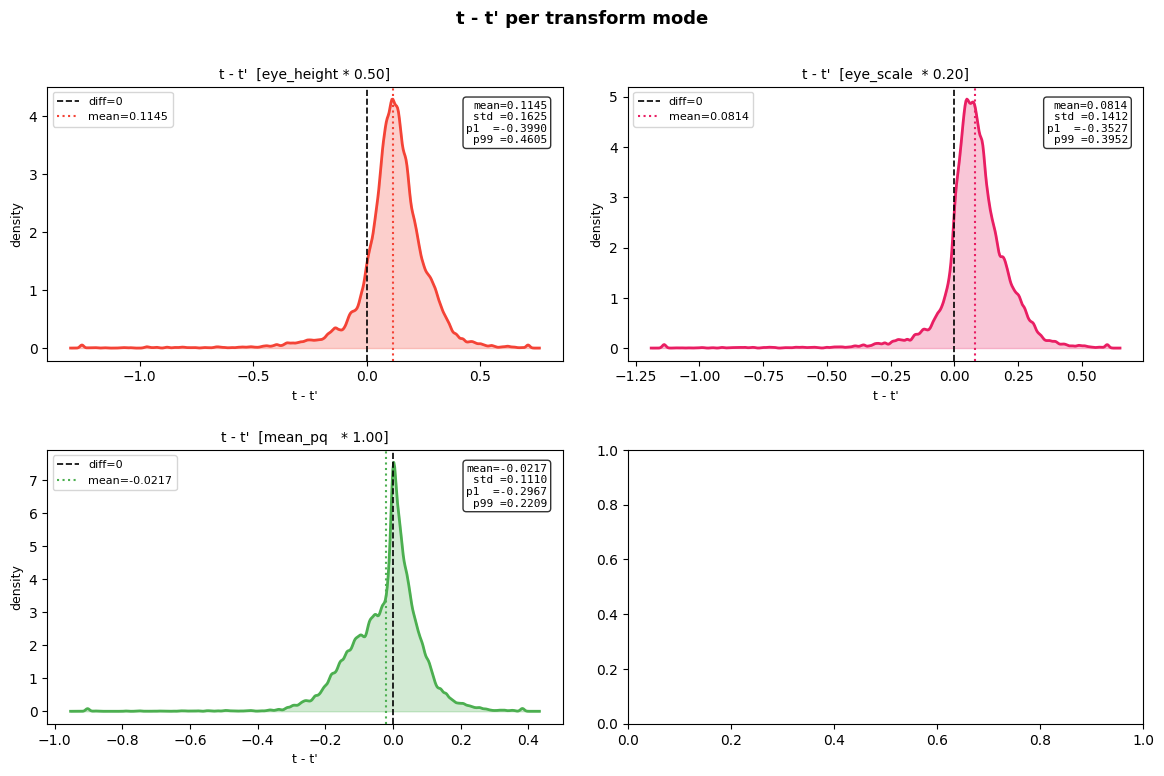


label                          mean       std        p1       p25       p75       p99
-------------------------------------------------------------------------------------
eye_height * 0.50            0.1145    0.1625   -0.3990    0.0572    0.1918    0.4605
eye_scale  * 0.20            0.0814    0.1412   -0.3527    0.0281    0.1458    0.3952
mean_pq   * 1.00            -0.0217    0.1110   -0.2967   -0.0786    0.0384    0.2209


In [3]:
diff_configs = {
    "eye_height * 0.50": ("eye_height",    0.50),
    "eye_scale  * 0.20": ("eye_scale",     0.20),
    "mean_pq   * 1.00":  ("mean_pq_dist",  1.00),
}

diffs = {}
for label, (mode, factor) in diff_configs.items():
    vals = []
    for rec in manifest:
        try:
            t_raw = float(rec["t"])
        except (ValueError, TypeError):
            continue
        px, py = float(rec["px"]), float(rec["py"])
        qx, qy = float(rec["qx"]), float(rec["qy"])
        _, _, _, _, t_prime, _ = compute_pq_rescale(px, py, qx, qy, t_raw, rec, mode, factor)
        vals.append(t_raw - t_prime)
    diffs[label] = np.array(vals)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
colors = ["#F44336", "#E91E63", "#4CAF50", "#FF9800"]

for ax, (label, d), color in zip(axes, diffs.items(), colors):
    lo, hi = np.percentile(d, 0.1), np.percentile(d, 99.9)
    x = np.linspace(lo - 0.05, hi + 0.05, 500)
    kde = gaussian_kde(np.clip(d, lo, hi), bw_method=0.05)
    ax.fill_between(x, kde(x), alpha=0.25, color=color)
    ax.plot(x, kde(x), color=color, lw=2)
    ax.axvline(0.0,       color="black", ls="--", lw=1.2, label="diff=0")
    ax.axvline(np.mean(d), color=color,  ls=":",  lw=1.5, label=f"mean={np.mean(d):.4f}")
    ax.set_title(f"t - t'  [{label}]", fontsize=10)
    ax.set_xlabel("t - t'", fontsize=9)
    ax.set_ylabel("density", fontsize=9)
    ax.legend(fontsize=8)
    stats = (
        f"mean={np.mean(d):.4f}\n"
        f"std ={np.std(d):.4f}\n"
        f"p1  ={np.percentile(d,1):.4f}\n"
        f"p99 ={np.percentile(d,99):.4f}"
    )
    ax.text(0.97, 0.95, stats, transform=ax.transAxes, ha="right", va="top",
            fontsize=8, family="monospace",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

fig.suptitle("t - t' per transform mode", fontsize=13, fontweight="bold")
plt.tight_layout(pad=2.0)
plt.show()

print(f"\n{'label':25s}  {'mean':>8}  {'std':>8}  {'p1':>8}  {'p25':>8}  {'p75':>8}  {'p99':>8}")
print("-" * 85)
for label, d in diffs.items():
    print(
        f"{label:25s}  {np.mean(d):8.4f}  {np.std(d):8.4f}  "
        f"{np.percentile(d,1):8.4f}  {np.percentile(d,25):8.4f}  "
        f"{np.percentile(d,75):8.4f}  {np.percentile(d,99):8.4f}"
    )